# Is it really unbound? Interstellar objects from their astrometry

**Science question.** Three objects are known to have come from outside the Solar System:
1I/ʻOumuamua (2017), 2I/Borisov (2019) and 3I/ATLAS (2025). What in the *observations* says so,
and how sure can we be? And why is an orbit with eccentricity above 1 not, by itself, proof of an
interstellar origin?

PyRoOrb treats an unbound orbit as something the data must **earn**:

1. **Bound first.** A free fit that lands at *e* > 1 is refitted with *e* held just below 1. The
   bound orbit is delivered unless the data refuse it at 3σ.
2. **Link bar.** A wrong linkage of tracklets is exactly what fits a hyperbola. So an unbound orbit
   needs at least 4 nights of data, unless the bound orbit is refused outright.
3. **Inbound reminder.** *e* > 1 *now* (osculating, heliocentric) does not mean *e* > 1 on the way
   in. A planetary encounter can supply a small energy excess. PyRoOrb flags orbits whose excess a
   giant planet could have provided.

Nothing is special-cased by designation: 1I, 2I and 3I earn their orbits the way an unknown
object would.

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import pyroorb

pyroorb.load_settings()       # the .env settings file (data folders), before the first fit

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.0


## Fit the three interstellar objects, and one impostor

The impostor is **C/1980 E1 (Bowell)**, the most hyperbolic *Solar System* comet known. It
was ejected after passing 0.23 au from Jupiter in 1980. Each fit takes seconds to a minute or two.

In [2]:
objects = {"1I/ʻOumuamua": "1I", "2I/Borisov": "2I", "3I/ATLAS": "C/2025 N1",
           "C/1980 E1 (Bowell)": "C/1980 E1"}
fits = {name: pyroorb.fit_orbit(pyroorb.fetch_observations(d), designation=d)
        for name, d in objects.items()}

In [3]:
MU = 2.9591220828559115e-4         # GM_sun [au^3 / day^2]
AU_PER_DAY_KMS = 1731.456836805556 # 1 au/day in km/s

print(f"{'object':20s} {'e':>16s} {'(e-1)/σ':>9s} {'q [au]':>7s} {'1/a [1/au]':>11s}"
      f" {'v∞ [km/s]':>9s} {'nongrav A1 [au/d²]':>20s} {'rms':>6s}")
for name, f in fits.items():
    e, se = f.eccentricity()
    a, sa = f.semimajor_axis()
    v_inf = np.sqrt(MU / abs(a)) * AU_PER_DAY_KMS       # speed far from the Sun
    ng = f.as_dict()
    a1 = (f"{ng['nongrav_params']['A1']:.2e} ± {ng['nongrav_sigmas']['A1']:.0e}"
          if ng["nongrav_model"] else "none")
    print(f"{name:20s} {e:9.6f} ± {se:.0e} {(e - 1) / se:9.0f} {f.perihelion_distance()[0]:7.3f}"
          f" {1 / a:11.5f} {v_inf:9.1f} {a1:>20s} {f.rms_residual():5.2f}\"")

object                              e   (e-1)/σ  q [au]  1/a [1/au] v∞ [km/s]   nongrav A1 [au/d²]    rms
1I/ʻOumuamua          1.200910 ± 6e-05      3292   0.256    -0.78513      26.4     2.87e-07 ± 4e-08  0.38"


2I/Borisov            3.356634 ± 2e-05    119533   2.007    -1.17447      32.3     1.17e-07 ± 6e-09  0.68"


3I/ATLAS              6.138897 ± 2e-05    340552   1.356    -3.78863      58.0     1.30e-07 ± 2e-09  0.55"
C/1980 E1 (Bowell)    1.057640 ± 9e-06      6170   3.364    -0.01713       3.9                 none  1.59"


All four are unbound by thousands of σ in their present osculating elements. The first
three also needed a **radial non-gravitational acceleration** (A1) to fit their astrometry. That
is ʻOumuamua's famous outgassing-without-a-coma signal, and PyRoOrb's model selection finds it
without being told.

The asymptotic speed v∞ separates them. The interstellar objects arrive at 26–58 km/s, typical
of stars in the solar neighbourhood. Bowell leaves at about 4 km/s, a speed Jupiter can impart.

## How sure? Sample the uncertainty

Draw orbits from each fit's covariance and count how many are bound (negative orbital energy).
`fit.bound_fraction()` does this for gravity-only fits. These fits carry a non-gravitational
parameter, so we draw the six orbital elements ourselves from the 6×6 state covariance.

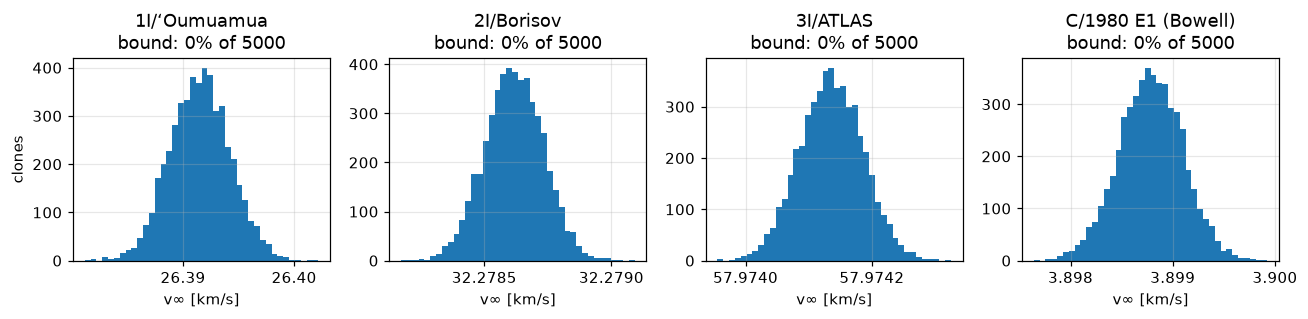

In [4]:
def energy_clones(fit, n=5000, seed=1):
    state = np.asarray(fit.state())[:6]                  # x, y, z [au], vx, vy, vz [au/day]
    cov = fit.covariance_matrix("state")[:6, :6]
    c = np.random.default_rng(seed).multivariate_normal(state, cov, size=n)
    return 0.5 * (c[:, 3:] ** 2).sum(1) - MU / np.linalg.norm(c[:, :3], axis=1)

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, (name, f) in zip(axes, fits.items()):
    eps = energy_clones(f)
    v_inf = np.sqrt(2 * eps) * AU_PER_DAY_KMS
    ax.hist(v_inf, bins=40, color="C0")
    ax.set(title=f"{name}\nbound: {np.mean(eps < 0):.0%} of 5000", xlabel="v∞ [km/s]")
    ax.ticklabel_format(useOffset=False)
    ax.locator_params(axis="x", nbins=3)
axes[0].set_ylabel("clones")
fig.tight_layout()
plt.show()

Not one clone is bound for any of the four: within the measurement uncertainty, all are
hyperbolic. Statistics cannot separate Bowell from the interstellar objects. Physics can: an
excess of 1/a ≈ −0.017 au⁻¹ is well within what a close Jupiter encounter can supply, and PyRoOrb
says so (rule 3, `hyperbolic.inbound_reminder`; internal API, may change):

In [5]:
# internal API, may change: the inbound-energy note
from pyroorb import hyperbolic

for name, f in fits.items():
    note = hyperbolic.inbound_reminder(f.elements(), f.element_sigmas()["e"], f.epoch_jd())
    print(f"{name}: " + (note["text"] if note else
          "excess energy beyond any planetary kick -- unbound on the way in too"))

1I/ʻOumuamua: excess energy beyond any planetary kick -- unbound on the way in too
2I/Borisov: excess energy beyond any planetary kick -- unbound on the way in too
3I/ATLAS: excess energy beyond any planetary kick -- unbound on the way in too
C/1980 E1 (Bowell): Unbound in its present osculating elements (e = 1.05764 ± 0.00001), but the excess (1/a = -0.01713 au⁻¹) is small enough for the planets to have supplied (its orbit passes within 0.01 au of Jupiter's). That does not make it interstellar: it may have arrived bound, and it could still lose energy on the way out. Check by moving the elements epoch a century or more before and after perihelion.


## Earning it: ʻOumuamua's first nights

Rule 1 matters most on the first nights, when a hyperbola is often just one of many orbits that
fit. We replay ʻOumuamua's discovery and fit the arc as it grew. `fit.unbound_check` (internal,
may change) records the decision: the free-fit eccentricity, how many σ the bound orbit was
refused by, and which orbit was kept.

In [6]:
obs_1i = pyroorb.fetch_observations("1I")
t0 = min(o["jd_utc"] for o in obs_1i)
replay = []
for days in (4.5, 5.5, 6.5, 7.5, 9.5, 12.5, 20, 30):
    sub = obs_1i.select(stop=t0 + days)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", pyroorb.UndeterminedOrbitWarning)
        f = pyroorb.fit_orbit(sub, designation="1I")
    uc = f.unbound_check
    replay.append((days, f.eccentricity(), uc))
    sig = f"{'>=' if uc.get('sigma_is_floor') else ''}{uc['sigma']:.1f}"
    print(f"{days:5.1f} d, {uc['nights']:2d} nights, {len(sub):3d} obs: free e = {uc['e_free']:.4f}; "
          f"bound orbit disfavoured at {sig:>6s} sigma -> kept {uc['kept']:7s}"
          f" (e = {f.eccentricity()[0]:.4f} ± {f.eccentricity()[1]:.4f})")

  4.5 d,  3 nights,   4 obs: free e = 1.2226; bound orbit disfavoured at    3.9 sigma -> kept bound   (e = 0.9999 ± 0.0696)


  5.5 d,  4 nights,  14 obs: free e = 1.1571; bound orbit disfavoured at    4.9 sigma -> kept unbound (e = 1.1571 ± 0.0454)


  6.5 d,  5 nights,  20 obs: free e = 1.1644; bound orbit disfavoured at    6.1 sigma -> kept unbound (e = 1.1644 ± 0.0364)


  7.5 d,  6 nights,  26 obs: free e = 1.1627; bound orbit disfavoured at    7.5 sigma -> kept unbound (e = 1.1627 ± 0.0284)


  9.5 d,  8 nights,  41 obs: free e = 1.1874; bound orbit disfavoured at >=10.0 sigma -> kept unbound (e = 1.1874 ± 0.0098)


 12.5 d, 12 nights,  99 obs: free e = 1.1971; bound orbit disfavoured at >=10.0 sigma -> kept unbound (e = 1.1971 ± 0.0027)


 20.0 d, 16 nights, 142 obs: free e = 1.1975; bound orbit disfavoured at >=10.0 sigma -> kept unbound (e = 1.1975 ± 0.0011)


 30.0 d, 20 nights, 157 obs: free e = 1.1992; bound orbit disfavoured at >=10.0 sigma -> kept unbound (e = 1.1992 ± 0.0002)


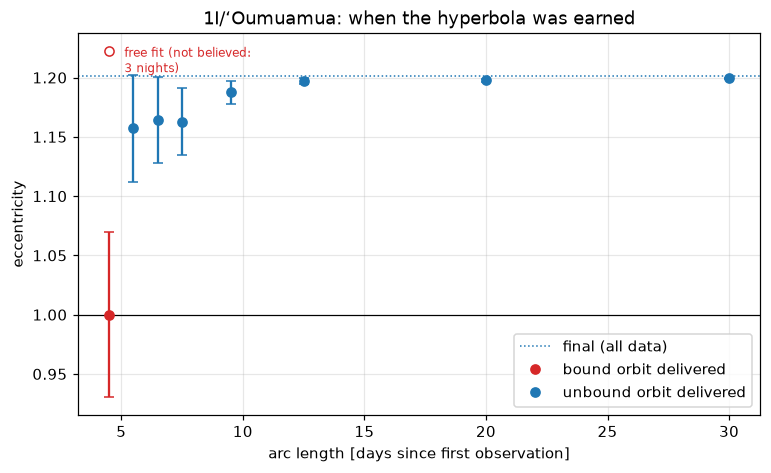

In [7]:
fig, ax = plt.subplots()
for days, (e, se), uc in replay:
    kept = uc["kept"] == "unbound"
    ax.errorbar(days, e, yerr=se, fmt="o", color="C0" if kept else "C3", capsize=3)
    if not kept:
        ax.plot(days, uc["e_free"], "o", mfc="none", color="C3")
        ax.annotate("free fit (not believed:\n3 nights)", (days, uc["e_free"]),
                    textcoords="offset points", xytext=(10, -14), fontsize=8, color="C3")
ax.axhline(1, color="k", lw=0.8)
ax.axhline(fits["1I/ʻOumuamua"].eccentricity()[0], color="C0", ls=":", lw=1,
           label="final (all data)")
ax.plot([], [], "o", color="C3", label="bound orbit delivered")
ax.plot([], [], "o", color="C0", label="unbound orbit delivered")
ax.set(xlabel="arc length [days since first observation]", ylabel="eccentricity",
       title="1I/ʻOumuamua: when the hyperbola was earned")
ax.legend(loc="lower right")
plt.show()

After three nights (4 observations) the free fit already wants *e* ≈ 1.2 and disfavours the bound
orbit at ~4σ. But three nights is below the link bar, and a 4σ preference from four observations
is not an outright refusal (that would take the stricter BIC test of rule 2). So PyRoOrb shows the
bound orbit, with *e* uncertain by ±0.07. From the fourth night the hyperbola is believed, and
it tightens onto the final value as the bound orbit becomes ever more strongly excluded (the
reported significance is capped at 10σ).

## Comparison with JPL

JPL Horizons gives the osculating elements of JPL's own solutions at each of our epochs.

In [8]:
import json, urllib.parse, urllib.request

HORIZONS_ID = {"1I": "DES=1I;", "2I": "DES=2I;CAP;NOFRAG", "C/2025 N1": "DES=C/2025 N1;CAP;NOFRAG",
               "C/1980 E1": "DES=C/1980 E1;CAP;NOFRAG"}

def horizons_elements(desig, jd_tdb):
    q = urllib.parse.urlencode({"format": "json", "COMMAND": f"'{HORIZONS_ID[desig]}'",
                                "EPHEM_TYPE": "ELEMENTS", "CENTER": "'500@10'",
                                "REF_PLANE": "ECLIPTIC", "TLIST": f"'{jd_tdb}'",
                                "TIME_TYPE": "TDB", "OUT_UNITS": "AU-D", "CSV_FORMAT": "YES"})
    res = json.load(urllib.request.urlopen("https://ssd.jpl.nasa.gov/api/horizons.api?" + q,
                                           timeout=60))["result"]
    row = res.split("$$SOE")[1].split("$$EOE")[0].split(",")
    return {"e": float(row[2]), "q": float(row[3])}     # CSV: JDTDB, date, EC, QR, ...

for name, f in fits.items():
    try:
        jpl = horizons_elements(objects[name], f.epoch_jd())
    except Exception as ex:
        print(name, "Horizons unavailable:", ex)
        continue
    (e, se), (q, sq) = f.eccentricity(), f.perihelion_distance()
    print(f"{name:20s} e: {e:.6f} vs JPL {jpl['e']:.6f} ({(e - jpl['e']) / se:+6.1f} σ)   "
          f"q: {q:.6f} vs JPL {jpl['q']:.6f} ({(q - jpl['q']) / sq:+6.1f} σ)")

1I/ʻOumuamua         e: 1.200910 vs JPL 1.200983 (  -1.2 σ)   q: 0.255894 vs JPL 0.255920 (  -1.0 σ)


2I/Borisov           e: 3.356634 vs JPL 3.356477 (  +7.9 σ)   q: 2.006543 vs JPL 2.006523 (  +7.8 σ)


3I/ATLAS             e: 6.138897 vs JPL 6.139336 ( -29.1 σ)   q: 1.356399 vs JPL 1.356449 ( -30.6 σ)


C/1980 E1 (Bowell)   e: 1.057640 vs JPL 1.057637 (  +0.2 σ)   q: 3.363943 vs JPL 3.363942 (  +0.1 σ)


### Does JPL's model close the gap for 2I and 3I?

JPL fits 2I and 3I with three non-gravitational components (A1, A2, A3) on an r⁻² law, plus a
time offset DT that shifts the outgassing peak away from perihelion. PyRoOrb's automatic choice
for both is a radial-only A1 on the water-ice law. It can be told to fit JPL's three components
on r⁻² (`nongrav="srp3"`; it has no DT). Refitting both that way, against JPL's published
parameters (SBDB):

In [9]:
for name in ("2I/Borisov", "3I/ATLAS"):
    d = objects[name]
    sb = json.load(urllib.request.urlopen("https://ssd-api.jpl.nasa.gov/sbdb.api?"
                                          + urllib.parse.urlencode({"sstr": d}), timeout=60))["orbit"]
    jp = {p["name"]: p for p in sb["model_pars"]}
    print(f"{name}: JPL solution {sb['orbit_id']}, {sb['n_obs_used']} observations, "
          + ", ".join(f"{k} {float(jp[k]['value']):.2e} ± {float(jp[k]['sigma']):.0e}"
                      for k in ("A1", "A2", "A3"))
          + f", DT {float(jp['DT']['value']):+.0f} ± {float(jp['DT']['sigma']):.0f} d")
    f3 = pyroorb.fit_orbit(pyroorb.fetch_observations(d), designation=d, nongrav="srp3")
    for label, f in (("automatic", fits[name]), ("A1-A3 on r^-2", f3)):
        jpl = horizons_elements(d, f.epoch_jd())
        (e, se), (q, sq) = f.eccentricity(), f.perihelion_distance()
        ng = f.as_dict()
        pars = ", ".join(f"{k} {v:.2e} ± {ng['nongrav_sigmas'][k]:.0e}"
                         for k, v in ng["nongrav_params"].items())
        print(f"  PyRoOrb {label:14s} {f.n_observations()} obs, rms {f.rms_residual():.3f}\"  "
              f"e - JPL {e - jpl['e']:+.1e} ({(e - jpl['e']) / se:+5.1f} σ)  "
              f"q - JPL {q - jpl['q']:+.1e} au ({(q - jpl['q']) / sq:+5.1f} σ)  [{pars}]")

2I/Borisov: JPL solution 54, 964 observations, A1 4.86e-08 ± 4e-09, A2 1.88e-08 ± 6e-09, A3 2.84e-09 ± 7e-10, DT -65 ± 11 d


  PyRoOrb automatic      2684 obs, rms 0.685"  e - JPL +1.6e-04 ( +7.9 σ)  q - JPL +2.0e-05 au ( +7.8 σ)  [A1 1.17e-07 ± 6e-09]


  PyRoOrb A1-A3 on r^-2  2571 obs, rms 0.652"  e - JPL +3.9e-04 ( +4.4 σ)  q - JPL +4.6e-05 au ( +3.8 σ)  [A1 2.84e-08 ± 3e-09, A2 2.15e-08 ± 7e-09, A3 -1.33e-08 ± 4e-09]


3I/ATLAS: JPL solution 55, 117 observations, A1 4.62e-08 ± 5e-09, A2 -9.56e-09 ± 2e-09, A3 -8.30e-09 ± 2e-09, DT +28 ± 9 d


  PyRoOrb automatic      7631 obs, rms 0.554"  e - JPL -4.4e-04 (-29.1 σ)  q - JPL -5.0e-05 au (-30.6 σ)  [A1 1.30e-07 ± 2e-09]


  PyRoOrb A1-A3 on r^-2  7570 obs, rms 0.464"  e - JPL +3.8e-04 (+22.6 σ)  q - JPL +3.6e-05 au (+21.3 σ)  [A1 1.58e-08 ± 2e-09, A2 3.41e-08 ± 1e-09, A3 -6.47e-09 ± 1e-10]


For ʻOumuamua JPL publishes A1 = (2.79 ± 0.36) × 10⁻⁷ au/d² (SBDB, solution with A1, A2, A3 on
an ≈ r⁻² law). PyRoOrb's radial-only fit gives (2.87 ± 0.37) × 10⁻⁷, the same detection.

### Caveats

* ʻOumuamua and Bowell agree with JPL within about 1σ. For 2I and 3I the eccentricities agree
  to a few parts in 10⁴ but not at the σ level: 8σ and 30σ of PyRoOrb's formal uncertainty
  with its automatic model. **JPL's model form does not close that gap** (the refit above):
  forcing A1, A2, A3 on r⁻² takes 2I to ~4σ only because the uncertainty grows, while the
  difference in *e* itself doubles, and it moves 3I to ~20σ on the *other* side of JPL. So the
  remaining difference is not just the choice of components. Two things the refit cannot match
  are still open: JPL's time offset DT (−65 d for 2I, +28 d for 3I), which PyRoOrb does not fit,
  and the data: SBDB lists JPL's solutions as using 964 and 117 observations, against PyRoOrb's
  roughly 2,600 and 7,600. For an active comet the non-gravitational model moves the orbit by
  more than the astrometry's formal uncertainty, so neither the elements nor the A1-A3 values
  of 2I and 3I can be compared with JPL's at the σ level.
* For 3I the three-component fit lowers the rms from 0.55" to 0.46", yet the automatic model
  selection stays with A1 alone. That choice is the engine's information-criterion ladder, not
  something this notebook tunes; the forced fit is shown for comparison, not as the better orbit.
* The clone sampling uses the 6×6 orbital block of the covariance, so it leaves out the A1
  coefficient's own uncertainty.
* "Unbound now" is in osculating heliocentric elements. The proper test of interstellar origin is
  the *original* orbit: integrated back to a few hundred au, in barycentric elements. For 1I–3I
  the excess is far beyond any planetary kick, so the conclusion does not depend on it; for
  Bowell it is the whole story.